# 01 - EDA: DDR Dataset (DR grading)

Thống kê số lượng ảnh, phân bố class, kích thước, độ sáng, độ tương phản và ảnh chất lượng thấp.
Toàn bộ logic nằm trong `src/eda.py` và `src/visualization.py`; kết quả lưu ở `outputs/eda/`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

%matplotlib inline
import numpy as np
import torch

from src import config, visualization as viz
viz.set_style()
from src import eda
from src.dataset import load_all

## 1. Tính thống kê cho từng ảnh

Đọc lại `outputs/eda/image_stats.csv` nếu đã có; đặt `RECOMPUTE = True` để tính lại từ ảnh.

In [2]:
RECOMPUTE = False

samples = load_all()
stats_path = config.EDA_DIR / "image_stats.csv"
if RECOMPUTE or not stats_path.exists():
    rows = eda.compute_dataset_stats(samples)
else:
    rows = eda.load_stats(stats_path)

thresholds = eda.flag_low_quality(rows)
summary = eda.summarize(rows, thresholds)
eda.save_csv(rows, stats_path)
eda.save_csv(summary["class_distribution"], config.EDA_DIR / "class_distribution.csv")
eda.save_json(summary, config.EDA_DIR / "eda_summary.json")
print("Total images:", summary["total_images"], summary["images_per_split"])

Total images: 400 {'train': 200, 'valid': 80, 'test': 120}


## 2. Số lượng và tỉ lệ từng class

label class            count  percent  train  valid  test
0     No DR               80   20.00%     40     16    24
1     Mild NPDR           80   20.00%     40     16    24
2     Moderate NPDR       80   20.00%     40     16    24
3     Severe NPDR         80   20.00%     40     16    24
4     PDR                 80   20.00%     40     16    24


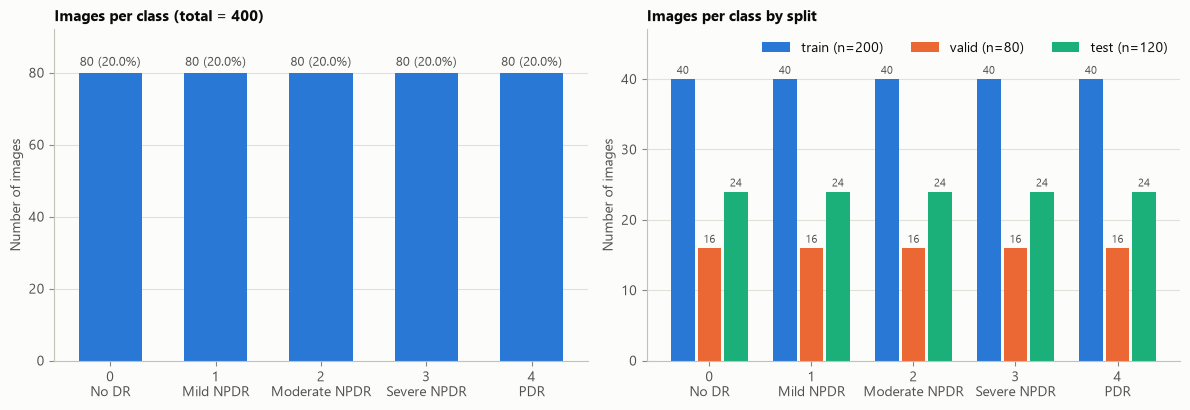

In [3]:
print(f"{'label':<6}{'class':<16}{'count':>6}{'percent':>9}{'train':>7}{'valid':>7}{'test':>6}")
for c in summary["class_distribution"]:
    print(f"{c['label']:<6}{c['class_name']:<16}{c['count']:>6}{c['percent']:>8.2f}%{c['train']:>7}{c['valid']:>7}{c['test']:>6}")
viz.plot_class_distribution(rows, config.EDA_DIR / "class_distribution.png");

## 3. Kích thước ảnh (width, height)

width         {'min': 1380.0, 'q1': 2048.0, 'median': 2592.0, 'q3': 2736.0, 'max': 5184.0, 'mean': 2556.34, 'std': 642.415}
height        {'min': 1137.0, 'q1': 1728.0, 'median': 1728.0, 'q3': 2000.0, 'max': 3456.0, 'mean': 1907.122, 'std': 477.548}
aspect_ratio  {'min': 0.995, 'q1': 1.323, 'median': 1.494, 'q3': 1.5, 'max': 1.51, 'mean': 1.349, 'std': 0.187}
unique resolutions: 39


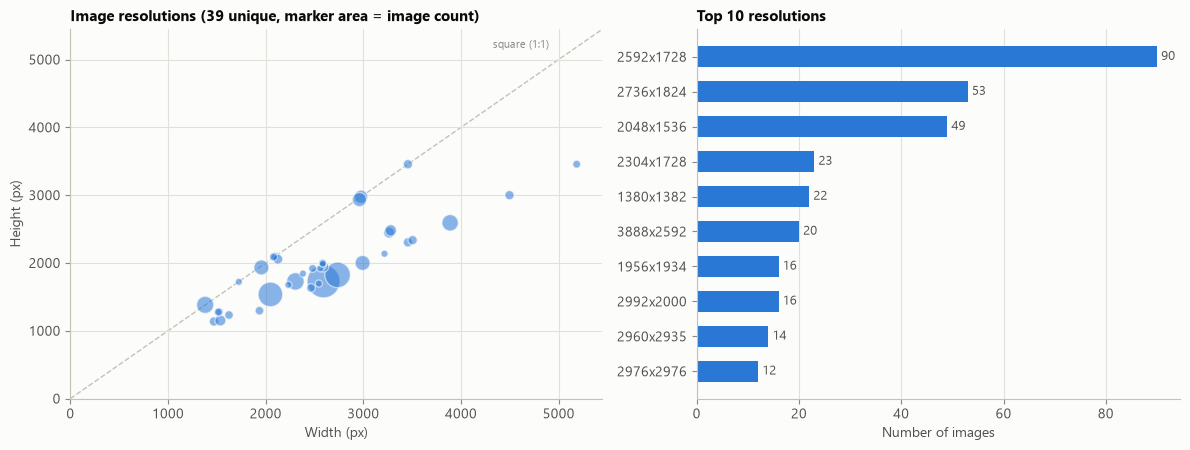

In [4]:
size = summary["image_size"]
for key in ("width", "height", "aspect_ratio"):
    print(f"{key:<13}", size[key])
print("unique resolutions:", size["unique_resolutions"])
viz.plot_image_sizes(rows, config.EDA_DIR / "image_sizes.png");

## 4. Độ sáng và độ tương phản

Độ sáng = mean grayscale, độ tương phản = std grayscale (thang 0-255). `_fg` chỉ tính trong vùng võng mạc (không bị nền đen kéo xuống), `_full` tính trên toàn ảnh.

brightness_fg    {'min': 22.707, 'q1': 73.673, 'median': 94.71, 'q3': 115.791, 'max': 199.339, 'mean': 97.924, 'std': 33.951}
contrast_fg      {'min': 9.197, 'q1': 19.956, 'median': 24.811, 'q3': 31.58, 'max': 102.808, 'mean': 26.251, 'std': 9.411}
brightness_full  {'min': 13.624, 'q1': 41.035, 'median': 51.035, 'q3': 67.55, 'max': 132.736, 'mean': 54.229, 'std': 19.05}
contrast_full    {'min': 13.748, 'q1': 38.155, 'median': 48.707, 'q3': 59.283, 'max': 102.808, 'mean': 50.427, 'std': 16.921}


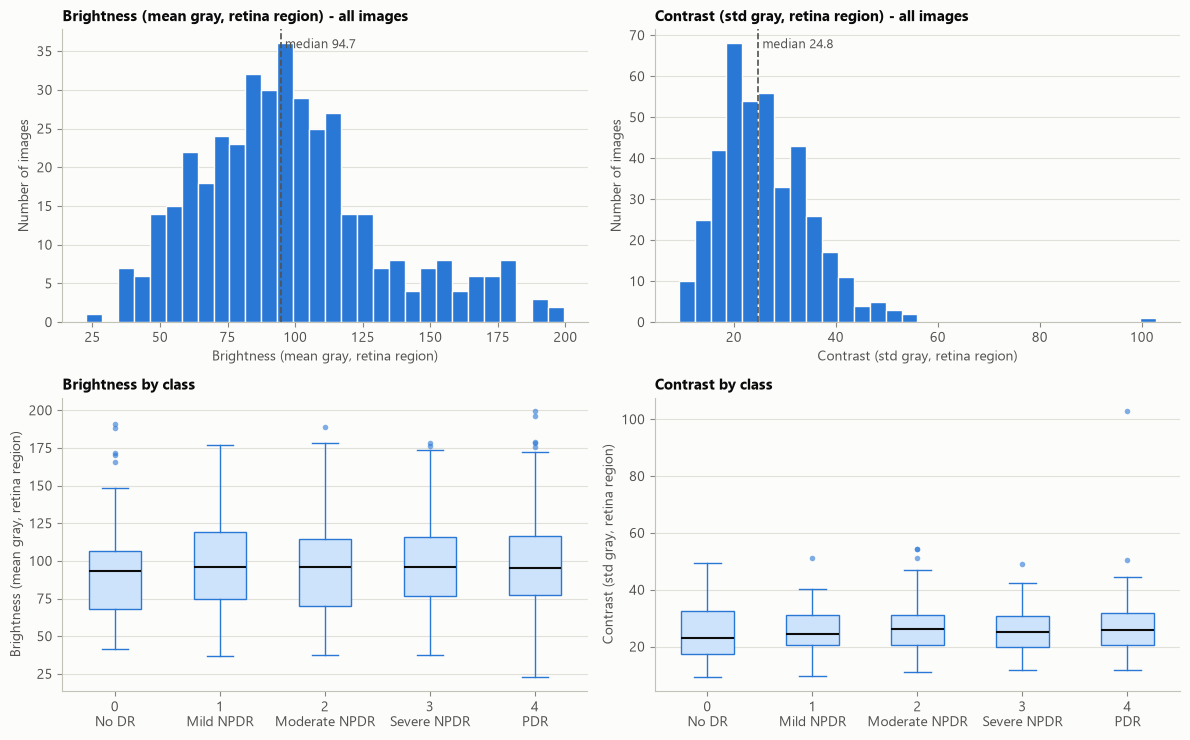

In [5]:
for key in ("brightness_fg", "contrast_fg", "brightness_full", "contrast_full"):
    print(f"{key:<16}", summary[key])
viz.plot_brightness_contrast(rows, config.EDA_DIR / "brightness_contrast.png");

## 5. Ảnh chất lượng thấp

Dataset không có nhãn chất lượng, nên các cờ dưới đây là **heuristic**: ảnh ngoại lệ theo Tukey fence (Q1 - 1.5·IQR, Q3 + 1.5·IQR) về độ sáng / tương phản / độ nét trong vùng võng mạc, hoặc ảnh không tìm được vùng võng mạc để crop. Đây là danh sách ảnh nên xem lại bằng mắt, không phải kết luận ảnh hỏng.

{'thresholds': {'method': 'Tukey fences, k=1.5', 'brightness_fg_low': 10.495, 'brightness_fg_high': 178.97, 'contrast_fg_low': 2.519, 'sharpness_low': 5.474}, 'total_flagged': 8, 'per_flag': {'too_dark': 0, 'too_bright': 5, 'low_contrast': 0, 'blurry': 2, 'crop_failed': 1}, 'per_class': {'No DR': 2, 'Mild NPDR': 0, 'Moderate NPDR': 1, 'Severe NPDR': 0, 'PDR': 5}}
train 007-6560-400.jpg class 4 ['too_bright']
valid 20170407111908406.jpg class 0 ['too_bright']
valid 007-6814-400.jpg class 4 ['too_bright']
test 20170414094409562.jpg class 0 ['too_bright']
test 20170518144607066.jpg class 2 ['too_bright']
test 007-7221-400.jpg class 4 ['blurry']
test 007-7052-400.jpg class 4 ['blurry']
test 007-7258-400.jpg class 4 ['crop_failed']


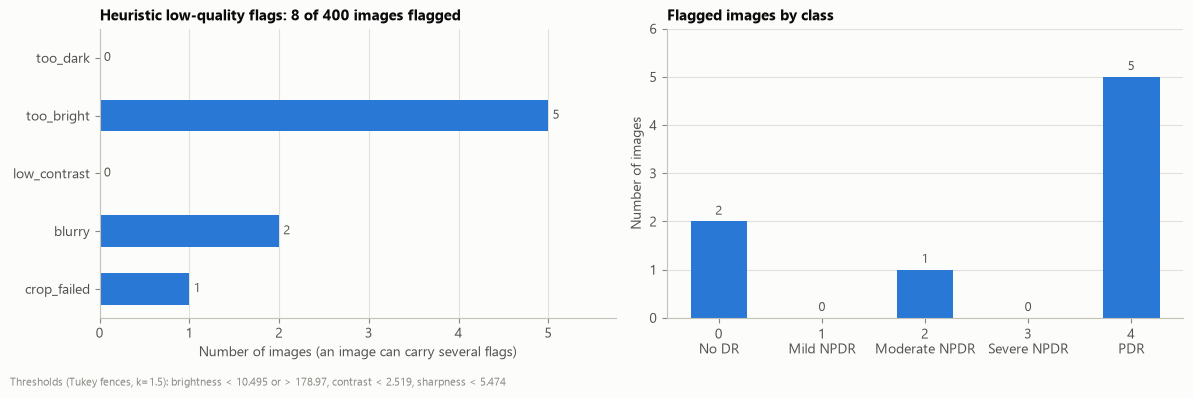

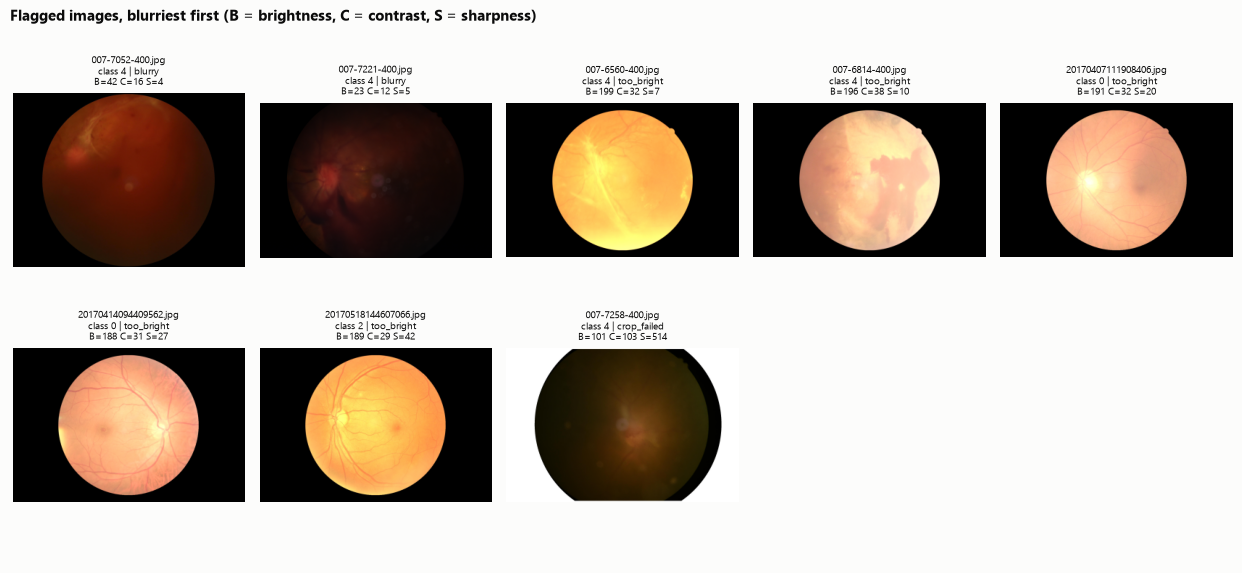

In [6]:
low = [r for r in rows if eda.is_low_quality(r)]
if low:
    eda.save_csv(low, config.EDA_DIR / "low_quality_images.csv")
print(summary["low_quality"])
for r in low:
    print(r["split"], r["filename"], "class", r["label"], [f for f in eda.QUALITY_FLAGS if r[f]])
viz.plot_low_quality(rows, thresholds, config.EDA_DIR / "low_quality_summary.png")
viz.plot_low_quality_examples(rows, config.EDA_DIR / "low_quality_examples.png");

## 6. Ảnh mẫu của từng class

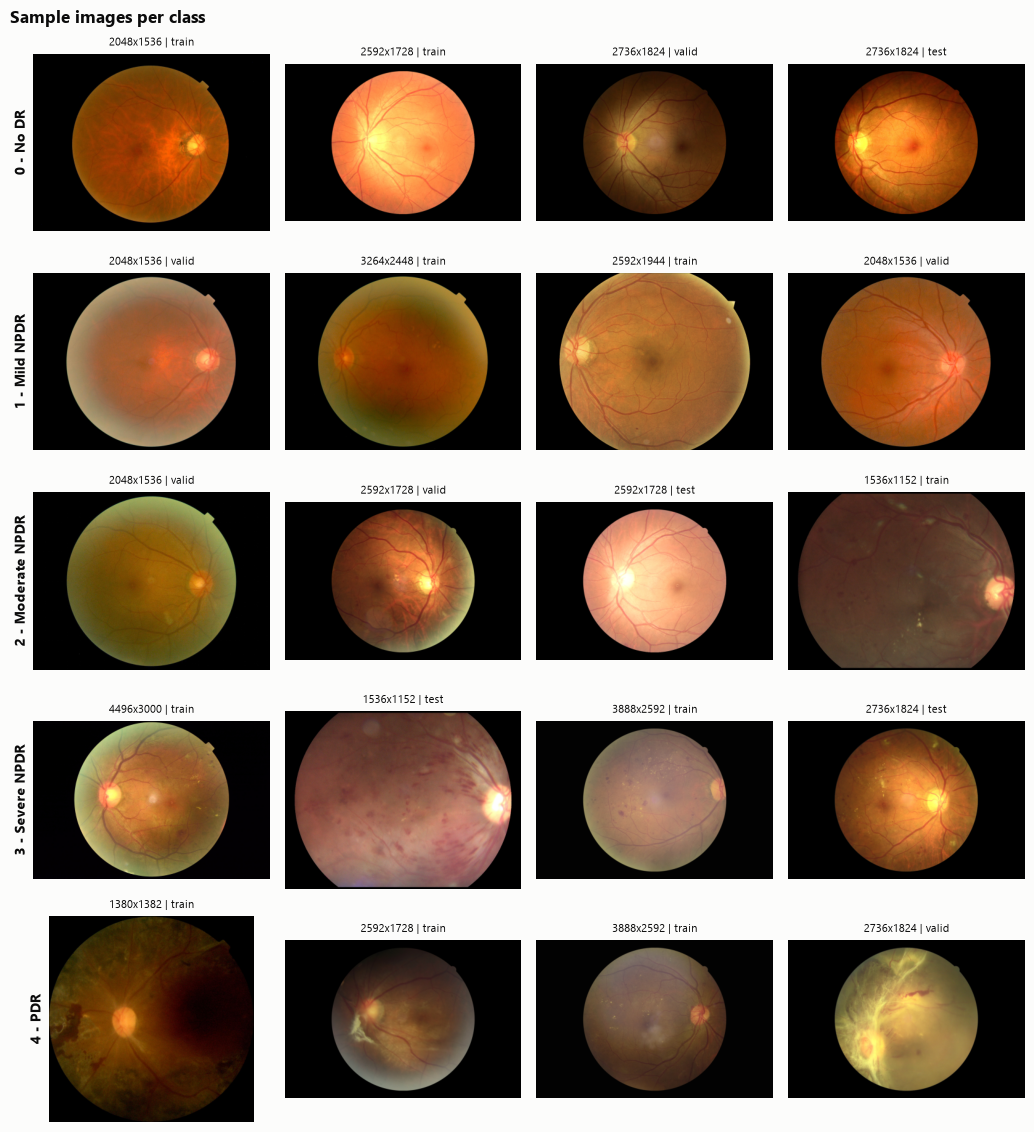

In [7]:
viz.plot_class_samples(samples, per_class=4, save_path=config.EDA_DIR / "class_samples.png");